In [5]:
from PIL import Image
import numpy as np

**reading an image and convert it to grayscale, normalize its pixels**

In [6]:
img = Image.open('Train_dataset/A/A1.jpg')
img = img.convert('L')
img_array = np.array(img, dtype=np.float32) / 255.0
img_array.shape

(200, 200)

In [7]:
img_array = img_array.flatten()
img_array.shape

(40000,)

### **Step 1 : Reading all files and adding a lable for each image**

In [8]:
from pathlib import Path

data_path = Path('Train_dataset/')
x = np.memmap(
    'x.npy',
    mode='w+',
    dtype=np.float32,
    shape=(87000, 784)
)
y = []
i = 0
for folder in data_path.iterdir():
    if folder.is_dir():
        for image_path in folder.glob('*.jpg'):
            img = Image.open(image_path).convert('L')
            img = img.resize((28, 28))
            img_array = np.array(img, dtype=np.float32) / 255.0
            x[i] = img_array.flatten()
            y.append(folder.name)
            i += 1
    x.flush()

In [9]:
y = np.array(y)
np.save('y.npy', y)

**for observabillty :**

In [10]:
print(f'X Shape : {x.shape}')
print(f'Y Shape : {y.shape}')
print(f'Number of classes : {len(np.unique(y))}')
print(f'Classes : {np.unique(y)}')

X Shape : (87000, 784)
Y Shape : (87000,)
Number of classes : 29
Classes : ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z' 'del' 'nothing' 'space']


### **Step 2**

**generate train and test data from orginal data**

In [11]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=0
)

**for observabillity :**

In [12]:
print(f'X.test shape : {x_test.shape} and Y.test shape : {y_test.shape}')
print(f'X.train shape : {x_train.shape} and Y.train shape : {y_train.shape}')

X.test shape : (17400, 784) and Y.test shape : (17400,)
X.train shape : (69600, 784) and Y.train shape : (69600,)


### Step 3

**training model and check it's accuracy**

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report


pline = Pipeline([
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

pline.fit(x_train, y_train)
y_pred = pline.predict(x_test)

print(f'The accuracy of model is : {accuracy_score(y_test, y_pred)}')
print(classification_report(y_test, y_pred))

The accuracy of model is : 0.9813218390804598
              precision    recall  f1-score   support

           A       0.97      0.97      0.97       587
           B       0.97      0.98      0.97       570
           C       1.00      0.99      1.00       602
           D       0.99      0.99      0.99       610
           E       0.95      0.96      0.95       591
           F       0.99      0.99      0.99       617
           G       0.99      0.99      0.99       573
           H       1.00      1.00      1.00       590
           I       0.97      0.98      0.98       596
           J       0.99      0.99      0.99       599
           K       0.96      0.97      0.96       624
           L       0.99      1.00      1.00       610
           M       0.98      0.98      0.98       605
           N       0.99      1.00      0.99       603
           O       0.99      0.98      0.99       615
           P       1.00      1.00      1.00       608
           Q       1.00      1.00  

**checking its accuracy in confusion matrix**

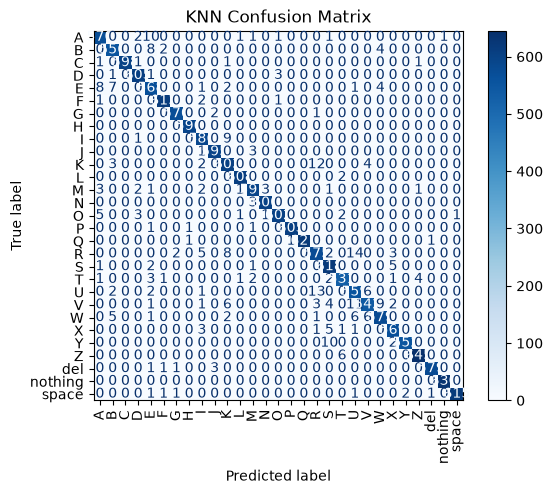

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation="vertical"
)

plt.title("KNN Confusion Matrix")
plt.show()